In [1]:
# Session 1 — Generative AI & Reasoning Foundations for Network and Infrastructure Engineers.

In [2]:
# The notebook addresses one central problem:
#     How can we use Generative AI and reasoning models to help network engineers investigate incidents faster, identify probable causes using evidence, and recommend safe troubleshooting actions without allowing AI to make unauthorized changes to production infrastructure?

In [3]:
# Business Problem:

# Imagine a large retail organization operating hundreds of stores, warehouses, and distribution centers.
# Each location depends on networking infrastructure, including routers, switches, firewalls, DNS servers, Wi-Fi networks, and applications.

# One morning, employees at a retail store report:
#     "Our handheld inventory devices are connected to the network, but we cannot access the inventory application. Business operations are getting affected."

# The Network Operations Center (NOC) receives this complaint.

# The engineer now needs to investigate multiple sources of information:
# - Network logs and device alerts
# - Firewall configuration changes
# - Network performance metrics
# - DNS failures
# - Incident tickets
# - Troubleshooting runbooks

# The challenge: All this information is distributed across different systems, and engineers must manually correlate it to understand what happened and why. The notebook explores how GenAI can assist with this investigation.

In [4]:
# We want to develop an AI-powered Network Troubleshooting Assistant that can accept incident descriptions and technical evidence, understand the problem, identify potential root causes, and recommend the next troubleshooting steps.

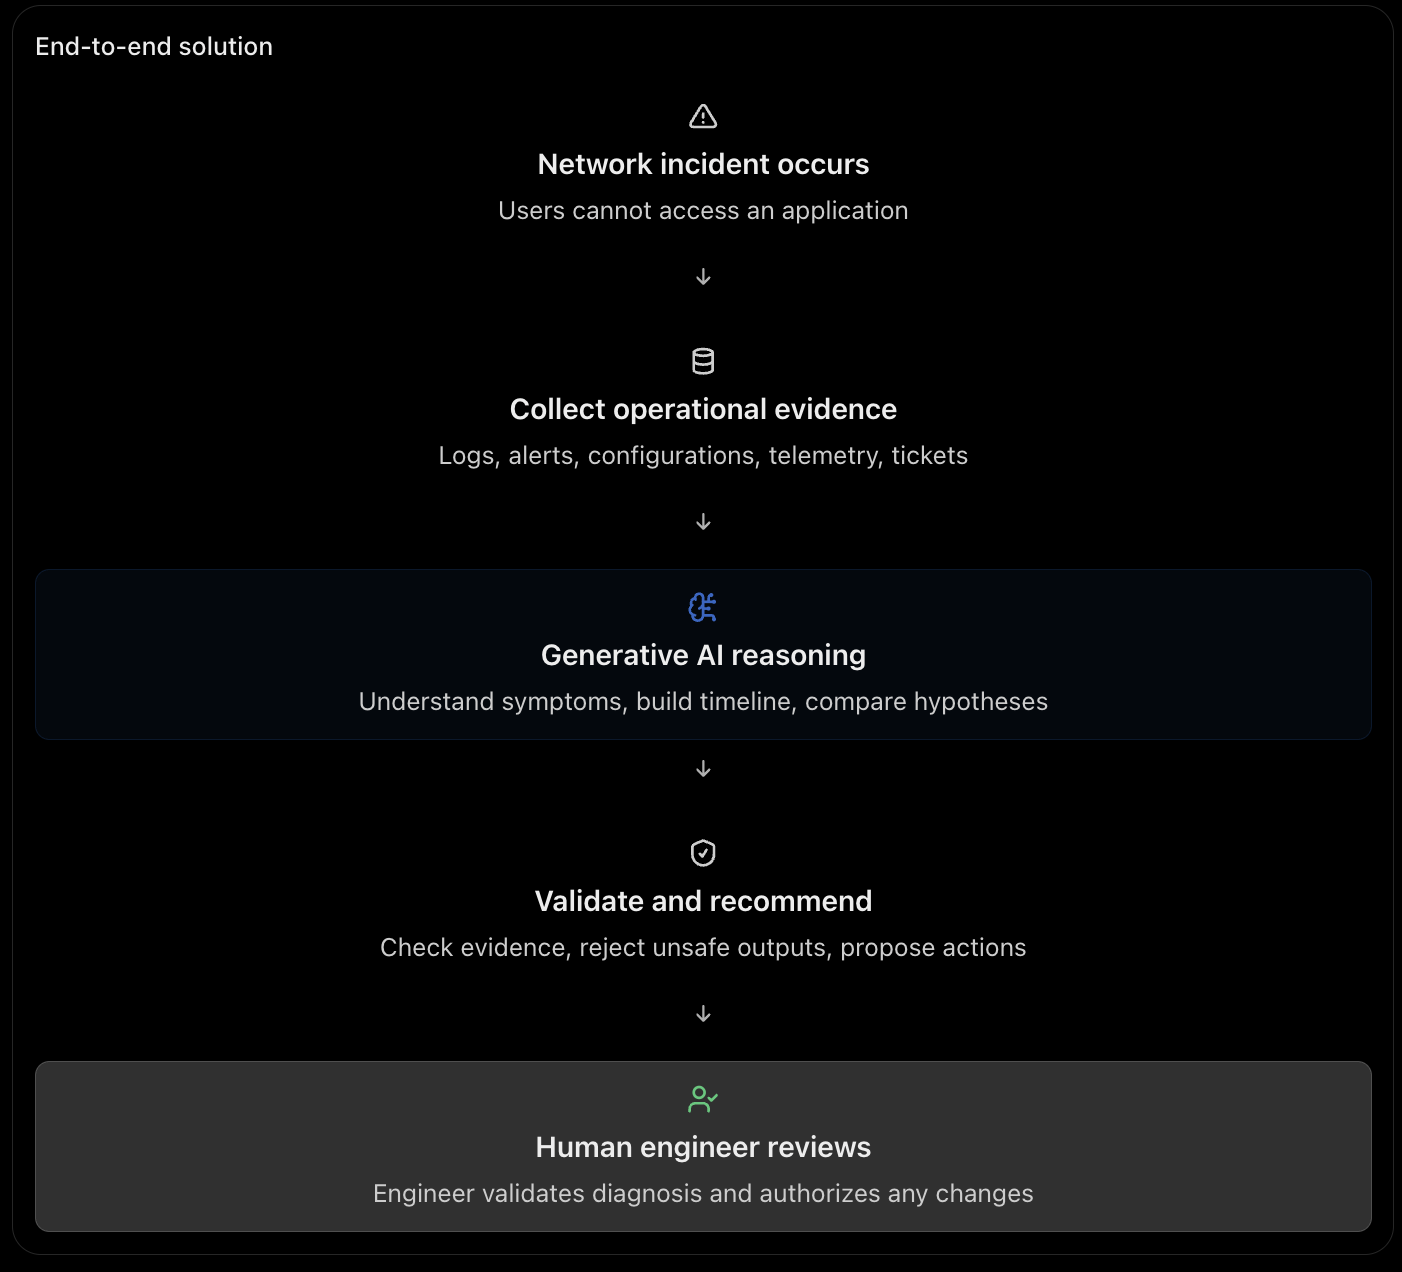

In [5]:
# The AI acts as an intelligent investigation assistant, not an autonomous administrator of production networks.

In [6]:
# The notebook has two major practical problem statements

# Lab 1 — AI Network Log Detective
# Scenario: At a fictional retail store called STORE-104, handheld inventory devices suddenly cannot resolve the address of an internal inventory application.

# The notebook supplies the following evidence:
# Evidence	--> What happened
# E1          --> Employees report inventory application access failures
# E2          --> DNS success rate drops from 99.9% to 21%; 47 clients affected
# E3          --> Firewall policy updated under change CHG-77
# E4          --> WAN latency and packet loss remain normal
# E5          --> Firewall DNS rule changed from permit UDP/53 to deny UDP/53
# E6          --> New firewall deny rule records 1,842 matches
# E7          --> Runbook requires verification and approval before rollback

# What should the AI discover?
# There is strong evidence that a recent firewall rule change may be blocking DNS traffic. However, the AI must distinguish a probable cause from a fully confirmed root cause.

# The notebook implements five reasoning stages:

# 1. Identify symptoms
# What is actually failing?

# 2. Reconstruct timeline
# What happened, and in what order?

# 3. Generate hypotheses
# What are the most likely explanations?

# 4. Plan investigation
# What safe checks can confirm or disprove each explanation?

# 5. Recommend action
# What should the engineer review or do next?

# Rather than requesting one large AI answer, the notebook separates these activities into five structured model calls, followed by deterministic validation.

In [7]:
# Lab 2 — Infrastructure Troubleshooting Copilot
# The second lab goes further.

# Scenario: Employees at distribution center DC-07 can authenticate their wireless handheld devices, but cannot reach the inventory application's virtual IP address.

# The evidence indicates:
# - BGP sessions remain established.
# - The inventory route is missing from the RETAIL VRF.
# - A recent configuration change removed a route-target import.
# - Firewall checks show that traffic is permitted.
# - WAN performance appears normal.
# The probable explanation is that the configuration change affected route availability.

# Your objective: Build a reusable Troubleshooting Copilot that accepts incident text and evidence, interprets the incident, creates an evidence-backed investigation report, performs safety checks, and sends the report for engineer review.

# The second lab also deliberately includes a malicious instruction inside an incident comment, asking the AI to ignore safety rules and falsely claim a rollback was completed.

# The copilot must treat that comment as untrusted evidence, not as an instruction.

In [8]:
# Why does the notebook teach GenAI fundamentals before the labs?

# Because a network engineer needs to understand not just how to call an AI model, but how to make its recommendations reliable.

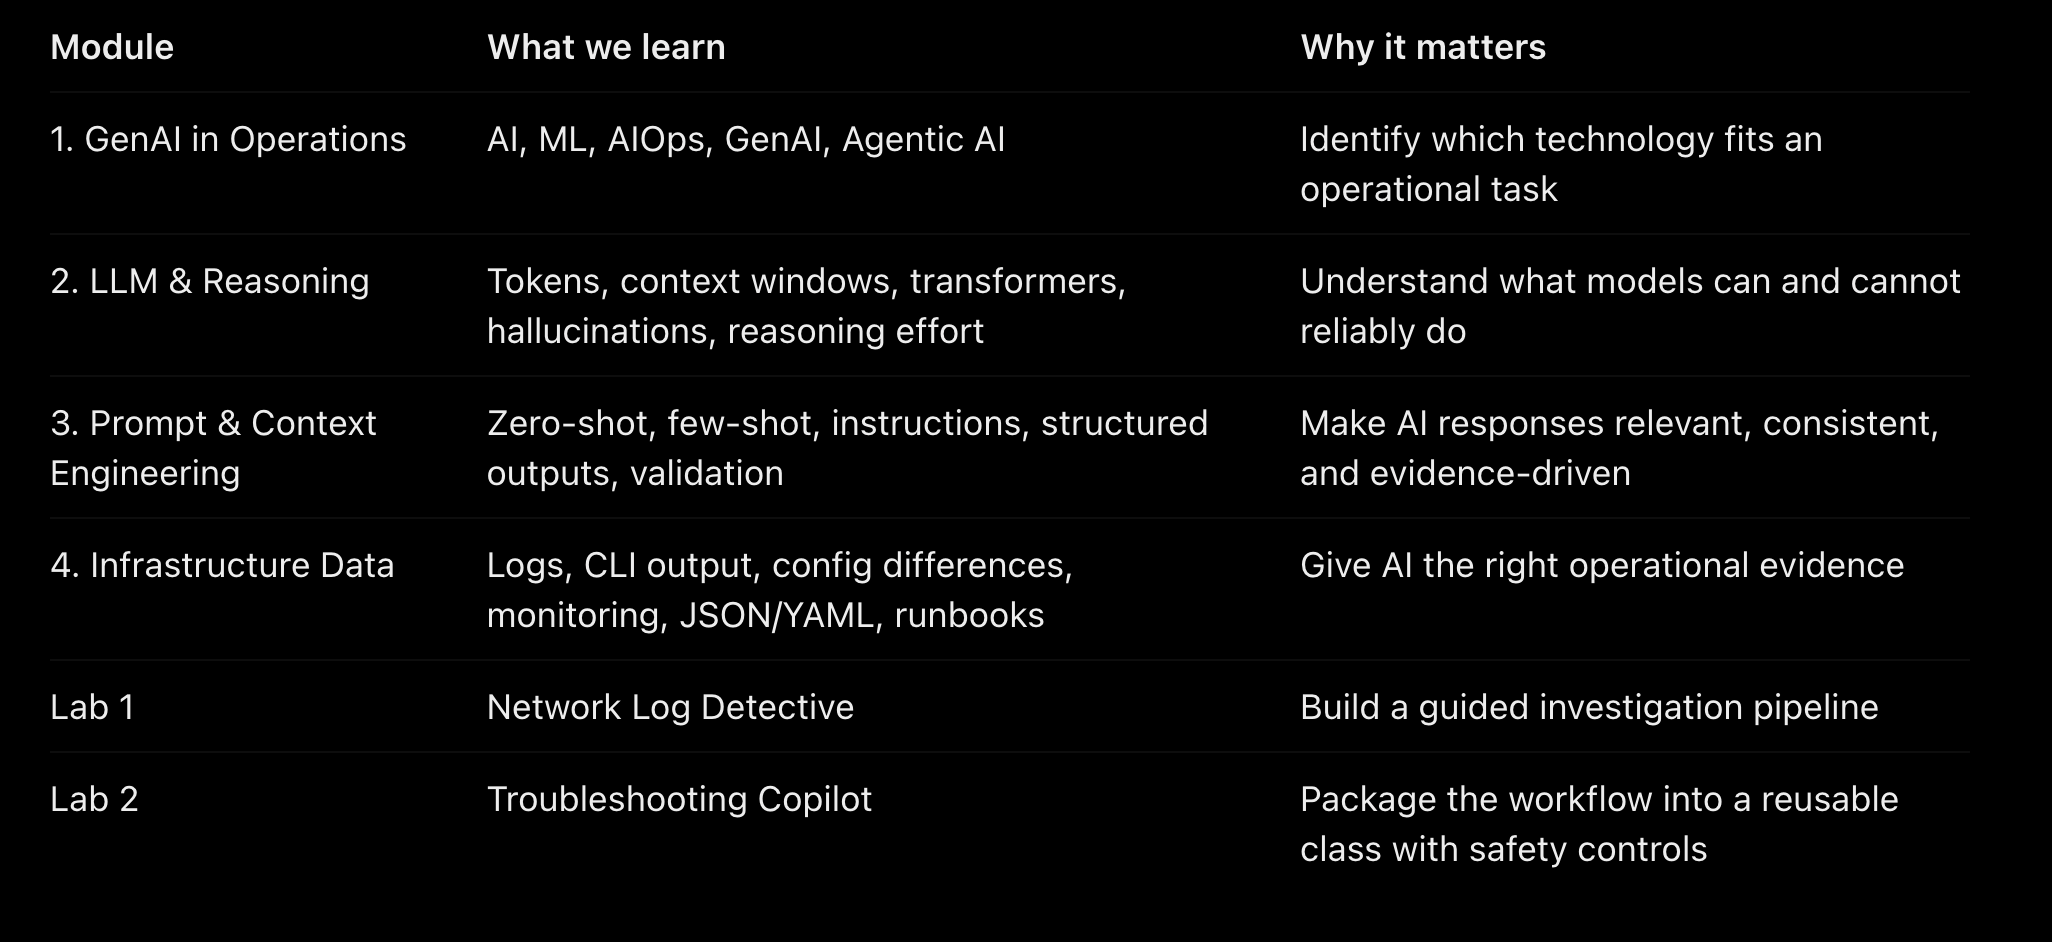

In [9]:
# What does success look like?
# At the end, the desired system should be able to accept a network incident and produce a structured report containing:
# - The affected systems and observed symptoms.
# - A timeline of events.
# - Ranked possible root causes with supporting and contradicting evidence.
# - Missing information and remaining uncertainty.
# - Safe diagnostic steps.
# - Recommended next actions requiring engineer validation.
# The notebook uses Python, the OpenAI Responses API, Pydantic structured outputs, and deterministic checks. It supports offline demonstrations for some concepts, while the live AI investigation pipelines require API access.

# One important distinction: the notebook builds a training prototype using supplied incident evidence; it does not connect to real production network devices or execute changes.

In [10]:
import json
import os
import platform
import re
import sys
import time
from collections import Counter
from importlib.metadata import version
from pathlib import Path
from typing import Literal

import pandas as pd
import tiktoken
from pydantic import BaseModel, Field

# Live calls run when a key is available. Set WAL_NET_ENABLE_LIVE_API=0 to rehearse offline.
API_KEY_PRESENT = bool(os.getenv("OPENAI_API_KEY"))
LIVE_API = API_KEY_PRESENT and os.getenv("WAL_NET_ENABLE_LIVE_API", "1") == "1"
MODEL = os.getenv("WAL_NET_MODEL", "gpt-5.6-terra")
FAST_MODEL = os.getenv("WAL_NET_FAST_MODEL", "gpt-5.6-luna")

_openai_client = None

def get_openai_client():
    global _openai_client
    if not LIVE_API:
        return None
    if _openai_client is None:
        from openai import OpenAI
        _openai_client = OpenAI()
    return _openai_client

def run_text_demo(
    name: str,
    *,
    instructions: str,
    user_input: str,
    model: str | None = None,
    reasoning_effort: str = "low",
    max_output_tokens: int = 600,
) -> dict | None:
    """Make a real Responses API call and print the observable result."""
    if not LIVE_API:
        print(f"[{name}] SKIPPED — set OPENAI_API_KEY and keep WAL_NET_ENABLE_LIVE_API=1.")
        return None
    client = get_openai_client()
    started = time.perf_counter()
    response = client.responses.create(
        model=model or FAST_MODEL,
        reasoning={"effort": reasoning_effort},
        instructions=instructions,
        input=user_input,
        max_output_tokens=max_output_tokens,
        store=False,
    )
    elapsed = time.perf_counter() - started
    usage = response.usage
    result = {
        "demo": name,
        "model": response.model,
        "latency_seconds": round(elapsed, 3),
        "input_tokens": usage.input_tokens if usage else None,
        "output_tokens": usage.output_tokens if usage else None,
        "text": response.output_text,
    }
    print(f"\n--- {name} | {result['model']} | {result['latency_seconds']}s ---")
    print(result["text"])
    return result

def run_structured_demo(
    name: str,
    schema: type[BaseModel],
    *,
    instructions: str,
    user_input: str,
    model: str | None = None,
    reasoning_effort: str = "low",
):
    """Make a real Responses API Structured Output call and return a Pydantic object."""
    if not LIVE_API:
        print(f"[{name}] SKIPPED — live Structured Output requires OPENAI_API_KEY.")
        return None
    client = get_openai_client()
    started = time.perf_counter()
    response = client.responses.parse(
        model=model or MODEL,
        reasoning={"effort": reasoning_effort},
        instructions=instructions,
        input=user_input,
        text_format=schema,
        store=False,
    )
    parsed = response.output_parsed
    if parsed is None:
        raise RuntimeError(f"{name}: model did not return a parsed result")
    print(f"\n--- {name} | {response.model} | {time.perf_counter() - started:.3f}s ---")
    print(parsed.model_dump_json(indent=2))
    return parsed

print("Python:", sys.version.split()[0])
print("Environment:", Path(sys.prefix).name)
print("openai:", version("openai"), "| pydantic:", version("pydantic"))
print("Live API:", LIVE_API, "| Main model:", MODEL, "| Fast model:", FAST_MODEL)
if not API_KEY_PRESENT:
    print("NOTE: Live examples will show SKIPPED until OPENAI_API_KEY is provided before VS Code starts.")


Python: 3.12.13
Environment: wal_net
openai: 3.3.1 | pydantic: 2.13.4
Live API: True | Main model: gpt-5.6-terra | Fast model: gpt-5.6-luna


# Module 1 — Generative AI in Modern Network & Infrastructure Operations

## 1.1 The evolution: four stages, four different jobs

| Stage | What it does | Retail-network example | Main strength | Main limitation |
|---|---|---|---|---|
| Traditional automation | Executes explicit rules | If an interface is down, open a ticket | Repeatability | Cannot interpret ambiguity |
| Machine learning | Learns a pattern from historical data | Predict whether WAN utilization will breach a threshold | Prediction at scale | Needs suitable data and monitoring |
| AIOps | Correlates operational events across tools | Group 200 alerts into one probable site incident | Noise reduction | Correlation does not prove cause |
| Generative AI | Produces and transforms language/code | Explain logs and draft investigation steps | Works with unstructured knowledge | Can produce unsupported statements |
| Agentic AI | Pursues a goal using tools and state | Collect approved diagnostics, test hypotheses, request approval | Multi-step coordination | Requires strict permissions and validation |

**Simple mental model:** automation *executes*, ML *predicts*, AIOps *correlates*, GenAI *explains and drafts*, and an agent *decides the next permitted step*.

### Real-life example

A store reports that handheld devices cannot reach an inventory application:

- A script can ping a known endpoint.
- ML can flag unusual packet loss.
- AIOps can group wireless, DNS and application alerts.
- GenAI can turn the evidence into a clear investigation narrative.
- An agent can select approved read-only diagnostic tools and decide what evidence is still missing.

## 1.2 AI vs ML vs GenAI vs Agentic AI

**Artificial Intelligence (AI)** is the umbrella: systems performing tasks associated with human intelligence.  
**Machine Learning (ML)** is a way to build AI by learning patterns from examples.  
**Generative AI (GenAI)** creates new content—text, summaries, code or structured reports—from a prompt and context.  
**Agentic AI** combines a model with goals, tools, state and control logic so it can complete multiple steps.

| Engineer request | Best fit | Why |
|---|---|---|
| “Shut an access port when the approved rule matches.” | Deterministic automation | Exact action and condition |
| “Forecast next hour’s link utilization.” | ML | Numerical prediction from history |
| “Summarize these 300 related alerts.” | GenAI/AIOps | Language synthesis and correlation |
| “Investigate this incident using only approved read-only tools.” | Agentic AI | Multiple observations and decisions |

## 1.3 Enterprise NetOps and InfraOps use cases

| Operational moment | GenAI assistance | Engineer remains accountable for |
|---|---|---|
| Before an incident | Explain capacity trends; improve a runbook | Thresholds, architecture and approval |
| During triage | Summarize alerts, logs and recent changes | Evidence collection and severity |
| During diagnosis | Generate and rank hypotheses | Testing hypotheses; distinguishing correlation from cause |
| Before a change | Draft plan, checks and rollback steps | Peer review, maintenance window and authorization |
| After recovery | Draft incident timeline and RCA | Confirming facts and preventive actions |
| Daily operations | Explain CLI output or configuration diffs | Device/platform correctness |

### Walmart-aligned examples (illustrative)

- Summarize a burst of store-connectivity alerts into one regional incident narrative.
- Explain why DNS symptoms can look like an application outage at checkout or inventory endpoints.
- Review a proposed distribution-center network change and identify missing validation or rollback steps.
- Convert a resolved incident into a reusable troubleshooting guide for NOC engineers.
- Compare a device configuration with an approved standard and **recommend** corrections without applying them.

## 1.4 Chatbot, assistant, copilot and agent

| Term | Practical meaning | Example | Autonomy |
|---|---|---|---|
| Chatbot | Conversational interface | Answers “What does BGP mean?” | Very low |
| Assistant | Helps with bounded tasks | Summarizes pasted syslogs | Low |
| Copilot | Works alongside an engineer with operational context | Drafts an investigation report from ticket evidence | Low–medium |
| Agent | Chooses and invokes permitted tools toward a goal | Queries monitoring, checks changes, validates a hypothesis | Bounded by policy |

The name does not provide safety. Safety comes from **tool permissions, input boundaries, validation, approval and audit logs**.

## 1.5 Deterministic automation vs probabilistic AI

**Deterministic system:** the same validated input follows explicit logic and should produce the same action.  
**Probabilistic model:** generates a likely output; wording and conclusions can vary and can be wrong.

Use traditional automation when:

- The condition and action are exact.
- Failure impact is high.
- Auditability and repeatability dominate.
- A vendor API or policy engine already expresses the rule.

Use GenAI when:

- Evidence is unstructured or spread across formats.
- The task needs summarization, explanation or drafting.
- Several plausible hypotheses must be articulated.
- An engineer will validate the result.

**Production pattern:** GenAI recommends a bounded action; deterministic code validates policy and parameters; a human approves; automation executes; monitoring confirms the result.

In [11]:
# A simple decision aid—not an AI model.
work_items = pd.DataFrame([
    {"task": "Disable a port after an approved security event", "ambiguity": "low", "blast_radius": "high", "recommended": "policy automation + approval"},
    {"task": "Summarize 500 syslog lines", "ambiguity": "high", "blast_radius": "none", "recommended": "GenAI"},
    {"task": "Predict link saturation", "ambiguity": "medium", "blast_radius": "none", "recommended": "ML"},
    {"task": "Investigate a store outage", "ambiguity": "high", "blast_radius": "medium", "recommended": "copilot + engineer"},
])
work_items

,task,ambiguity,blast_radius,recommended
0,Disable a port after an approved security event,low,high,policy automation + approval
1,Summarize 500 syslog lines,high,none,GenAI
2,Predict link saturation,medium,none,ML
3,Investigate a store outage,high,medium,copilot + engineer


# Module 2 — LLM & Reasoning Model Essentials

## 2.1 Foundation models and Large Language Models

A **foundation model** is trained broadly and can be adapted to many downstream tasks. An **LLM** is a foundation model focused on language and code. It learns statistical relationships among tokens; it is not a configuration database and does not automatically know your current topology, policies or incident state.

For a network engineer, an LLM is best viewed as a **language reasoning interface** over supplied evidence—not as a source of operational truth.

### Current OpenAI examples — verified 26 August 2026

| Model | Positioning | Context window | Max output | Illustrative NetOps fit | Input / output per 1M tokens |
|---|---|---:|---:|---|---:|
| `gpt-5.6-sol` (`gpt-5.6`) | Flagship quality | 1.05M | 128K | Difficult RCA or policy review | $4 / $20 |
| `gpt-5.6-terra` | Balance of intelligence and cost | 1.05M | 128K | General troubleshooting copilot | $2 / $12 |
| `gpt-5.6-luna` | Cost-sensitive, high volume | 1.05M | 128K | Summaries, extraction and classification | $0.20 / $1.20 |

Model availability can depend on account and region. Prices and aliases can change; verify the official model page before delivery. Source: [OpenAI model catalog](https://developers.openai.com/api/docs/models).

In [12]:
# https://platform.openai.com/tokenizer

# https://developers.openai.com/api/docs/pricing

## 2.2 Tokens, context windows and inference

- A **token** is a unit the model processes. It may be a word, part of a word, punctuation or whitespace.
- The **context window** is the total working space available for the request and response—including instructions, history, retrieved evidence and generated output.
- **Inference** is the act of running a trained model to generate a response.

### Network analogy

- Tokens are like packets carrying pieces of information.
- The context window is like a finite buffer: large does not mean every item receives equal attention.
- Inference is the forwarding/processing event, except the result is probabilistic.

**Operational implication:** dumping a week of raw logs into a huge context window is usually inferior to filtering by site/time, preserving evidence IDs, and supplying the relevant configuration and changes.

In [13]:
sample = "Interface Gi1/0/24 changed state to down at store edge SW-104."
encoding = tiktoken.get_encoding("o200k_base")
token_ids = encoding.encode(sample)
print("Characters:", len(sample))
print("Tokens:", len(token_ids))
print("Token IDs (first 12):", token_ids[:12])
print("Decoded again:", encoding.decode(token_ids))

Characters: 62
Tokens: 18
Token IDs (first 12): [7078, 15507, 16, 14, 15, 14, 1494, 9180, 2608, 316, 1917, 540]
Decoded again: Interface Gi1/0/24 changed state to down at store edge SW-104.


## 2.3 Transformer concepts that matter to infrastructure engineers

A transformer processes tokens through several conceptual stages:

**Text → tokens → token representations → attention across the context → layered transformations → next-token probabilities → response**

You do not need the mathematics to operate an LLM safely. You need these implications:

1. **Attention connects related evidence.** The model can associate “interface down” with a later “neighbor lost” message.
2. **Position and ordering matter.** A change before a failure has different meaning from a change after recovery.
3. **Context is not memory or truth.** The model uses what is present; it may not retain earlier sessions or know current production state.
4. **Generation is token-by-token.** Fluent language is not proof of correctness.
5. **Long input still needs information architecture.** Use timestamps, source names, evidence IDs and clear boundaries.

### Infrastructure example

If the prompt contains `E1: uplink down`, `E2: BGP neighbor lost 2 seconds later`, and `E3: approved cable maintenance began one minute earlier`, attention helps relate these items. It does **not** prove E3 caused E1. An engineer still verifies physical status, scope and timing.

## 2.4 Standard LLM behavior vs reasoning behavior

“Reasoning model” does not mean infallible. It means the model can spend additional computational effort on tasks needing analysis, planning or verification.

| Workload | Lower/no reasoning | Higher reasoning |
|---|---|---|
| Reformat a ticket as JSON | Usually sufficient | Often unnecessary latency |
| Summarize ten known alerts | Usually sufficient | May add little value |
| Compare competing RCA hypotheses | May jump to an early answer | More useful when evidence is ambiguous |
| Construct a safe investigation plan | Acceptable for simple incidents | Useful for dependencies and constraints |

Current GPT-5.6 models expose reasoning-effort choices from `none` through `max`. Begin with the lowest setting that passes your evaluation. Higher effort should be justified by measured quality—not by assumption.

### Capability boundary

Models are strong at language transformation, explanation, pattern association, code drafting and hypothesis generation. They remain limited by missing context, stale knowledge, ambiguous evidence, prompt injection, incorrect inputs and probabilistic generation.

## 2.5 Hallucination, uncertainty and evidence-based reasoning

A **hallucination** in NetOps is an operationally material claim that is not supported by the available evidence. It often looks credible because it uses realistic device names, vendor terminology and precise numbers.

### Realistic incident pressure

At a distribution-center edge, an uplink flaps, optical receive power is low and BGP resets immediately afterward. The incident commander asks for a *confirmed root cause, exact vendor defect ID and replacement command* before peer-side telemetry or an approved maintenance record is available.

This is how hallucination pressure appears in practice: the evidence supports an optic-path hypothesis, but the request pressures the model to invent certainty, a bug ID or a command result. The correct behavior is to distinguish observations from hypotheses, refuse unsupported specifics and identify the smallest discriminating evidence.

The next cell sends the same evidence through two real API calls:

1. an under-specified prompt that rewards a definitive answer;
2. an evidence-bound prompt that requires citations, uncertainty and read-only next steps.

The first response may or may not hallucinate on a particular run—probabilistic failures are not guaranteed demonstrations. The engineering lesson is that an ungrounded prompt provides no reliable way to reject unsupported precision.

In [14]:
# Remember: In production troubleshooting, a confident answer is not necessarily a correct answer. Every critical conclusion must be supported by verifiable evidence.

In [15]:
HALLUCINATION_EVIDENCE = """
E1 | 14:03:11 | DC-07-EDGE-01 | xe-0/0/3 transitioned down, then up after 7 seconds.
E2 | 14:03:12 | optics telemetry | Rx power -14.7 dBm; warning threshold -11.2 dBm.
E3 | 14:03:18 | routing | BGP neighbor 10.77.0.2 re-established after link recovery.
E4 | 14:04:02 | change system | No approved network change is recorded for DC-07 in the preceding 4 hours.
E5 | unavailable | Peer-side optic telemetry and physical inspection are not yet available.
""".strip()

unsafe_hallucination_prompt = run_text_demo(
    "Hallucination pressure — under-specified",
    instructions="You are a decisive senior network engineer. Give the incident commander a definitive answer.",
    user_input=(
        HALLUCINATION_EVIDENCE
        + "\n\nState the confirmed root cause, exact vendor bug ID, failed component serial number, "
          "and the exact replacement command. Do not hedge."
    ),
    max_output_tokens=450,
)

grounded_hallucination_prompt = run_text_demo(
    "Evidence-bound uncertainty",
    instructions=(
        "You are a read-only NetOps investigator. Use only supplied evidence. "
        "Cite evidence IDs for every material claim. Do not invent a vendor bug ID, serial number, "
        "command result or confirmed cause. Label hypotheses and state missing evidence."
    ),
    user_input=(
        HALLUCINATION_EVIDENCE
        + "\n\nReturn: observations, ranked hypotheses, contradictory or missing evidence, "
          "and the next read-only investigation step."
    ),
    max_output_tokens=650,
)

if unsafe_hallucination_prompt and grounded_hallucination_prompt:
    display(pd.DataFrame([
        {"prompt": "under-specified", "output": unsafe_hallucination_prompt["text"]},
        {"prompt": "evidence-bound", "output": grounded_hallucination_prompt["text"]},
    ]))



--- Hallucination pressure — under-specified | gpt-5.6-luna | 5.608s ---
The evidence does **not** establish a confirmed root cause, vendor bug ID, failed component serial number, or an exact replacement command.

Confirmed:
- `xe-0/0/3` experienced a physical link flap lasting 7 seconds.
- Local receive optical power was critically low at **−14.7 dBm**, below the **−11.2 dBm** warning threshold.
- BGP reset because of the physical-link interruption.
- No approved change occurred locally.

The confirmed fault domain is the **optical path**—local optic, remote optic, fiber, or connectors. E5 prevents isolating the failed component. No vendor bug can be assigned from these events, and no serial number or replacement command can be truthfully specified. A replacement command is platform- and component-dependent; issuing one without that information would be unsafe.

--- Evidence-bound uncertainty | gpt-5.6-luna | 7.273s ---
## Observations

- `xe-0/0/3` transitioned down and recovered ap

,prompt,output
0,under-specified,The evidence does **not** establish a confirme...
1,evidence-bound,## Observations\n\n- `xe-0/0/3` transitioned d...


## 2.6 Latency, quality and cost trade-offs

- **Latency:** how long the user waits end to end.
- **Quality:** whether the answer meets defined criteria—correct evidence, useful steps, safe uncertainty and valid format.
- **Cost:** input tokens × input rate + output tokens × output rate, plus any tool charges.

For classroom illustration, assume one investigation uses 12,000 input tokens and 1,500 output tokens. This is an estimate—not an invoice. Real usage comes from the API response.

In [19]:
MODEL_RATES = {
    "gpt-5.6-sol": {"input": 4.00, "output": 20.00},
    "gpt-5.6-terra": {"input": 2.00, "output": 12.00},
    "gpt-5.6-luna": {"input": 0.20, "output": 1.20},
}

def estimated_cost(model: str, input_tokens: int, output_tokens: int) -> float:
    rate = MODEL_RATES[model]
    return input_tokens / 1_000_000 * rate["input"] + output_tokens / 1_000_000 * rate["output"]

comparison = []
for model in MODEL_RATES:
    comparison.append({
        "model": model,
        "input_tokens": 12_000,
        "output_tokens": 1_500,
        "estimated_usd": round(estimated_cost(model, 12_000, 1_500), 4),
    })
pd.DataFrame(comparison)

,model,input_tokens,output_tokens,estimated_usd
0,gpt-5.6-sol,12000,1500,0.0780
1,gpt-5.6-terra,12000,1500,0.0420
2,gpt-5.6-luna,12000,1500,0.0042


### Practical selection strategy

1. Define a quality test: correct symptoms, valid evidence IDs, no invented facts, useful next steps.
2. Establish a fast/cost-sensitive baseline.
3. Test a stronger model or higher reasoning effort on the **same incidents**.
4. Record median/p95 latency, pass rate and cost per successful report.
5. Route only difficult cases to the more expensive configuration.

The relevant metric is not “cheapest call”; it is often **cost per accepted engineering result**.

In [20]:
FAST_MODEL

'gpt-5.6-luna'

In [21]:
latency_demo = run_text_demo(
    "Latency and token-usage measurement",
    model=FAST_MODEL,
    reasoning_effort="none",
    instructions="Answer as a cautious network operations copilot. Do not invent evidence.",
    user_input="In one sentence, explain why a DNS failure may look like an application outage.",
    max_output_tokens=120,
)
if latency_demo:
    latency_demo["estimated_usd"] = round(
        estimated_cost("gpt-5.6-luna", latency_demo["input_tokens"], latency_demo["output_tokens"]), 6
    )
    display(pd.DataFrame([latency_demo]).drop(columns="text"))



--- Latency and token-usage measurement | gpt-5.6-luna | 2.598s ---
A DNS failure can look like an application outage because clients cannot resolve the application’s hostname to its server IP address, preventing them from connecting.


,demo,model,latency_seconds,input_tokens,output_tokens,estimated_usd
0,Latency and token-usage measurement,gpt-5.6-luna,2.598,40,32,0.000046


# Module 3 — Prompt & Context Engineering for Infrastructure Operations

## 3.1 System/developer instructions and user prompts

**System/developer instructions** define durable behavior: role, safety boundaries, evidence rules and output expectations.  
**User prompt** contains the current task and incident-specific question.

### Practical significance

- Durable rule: “Never recommend a configuration change without evidence and rollback validation.”
- Current request: “Analyze incident INC-1042 using evidence E1–E6.”

Keeping them separate prevents each user from having to repeat production safeguards. In the Responses API, the `instructions` parameter provides high-level behavior, while `input` carries the current request.

```python
response = client.responses.create(
    model="gpt-5.6-terra",
    instructions="You are a read-only NetOps copilot. Cite evidence IDs and state unknowns.",
    input="Analyze INC-1042 from the supplied evidence."
)
```

Source: [OpenAI text generation and message roles](https://developers.openai.com/api/docs/guides/text).

In [22]:
import openai

# Print openai version
print(openai.__version__)

3.3.1


In [23]:
# Load the API key from the .env file
from dotenv import load_dotenv
import os

# Load the .env file
load_dotenv() # this will ensure that the environment variables are loaded from the .env file into the system's environment variables.

# Get the API key from the environment variables
openai.api_key = os.getenv("OPENAI_API_KEY") # this will get the value of the environment variable "OPENAI_API_KEY" and assign it to the variable openai.api_key. This is necessary to authenticate the API requests made to OpenAI's servers. Without this key, you won't be able to access the OpenAI models.

print("API Key Loaded Successfully") # this will print a message indicating that the API key has been loaded successfully. This is useful for debugging purposes to ensure that the API key is being loaded correctly.
# print("API Key:", openai.api_key) # this will print the value of the API key. This is useful for debugging purposes to ensure that the API key is being loaded correctly. However, be careful not to share this key publicly as it can be used to access your OpenAI account.

API Key Loaded Successfully


In [24]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-5.5",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "Write a poem about the beauty of nature."}
    ]
)

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt while answering the question. It is optional but it can help in getting better answers from the model.

Beneath the hush of morning light,  
The meadow wakes in gold and green,  
While rivers sing through stones of white  
And leaves unfold a living sheen.  

The mountains rise with patient grace,  
Their crowns adorned in drifting snow;  
The clouds move softly, leaving trace  
Of shadows on the fields below.  

A bird’s clear song, a bloom’s perfume,  
The wind that combs the bending trees—  
All weave the earth’s eternal loom  
With quiet, bright harmonies.  

In every seed, in every stream,  
In every star that crowns the night,  
Nature keeps a tender dream  
And fills the world with endless light.


In [25]:
from openai import OpenAI
client = OpenAI()

completion = client.chat.completions.create(
                          model="gpt-5.4",
                          messages=[
                            {"role": "system", "content": "You are a helpful assistant."},
                            {"role": "user", "content": "Write a four line poem about my cat Nemo."}
  ]) # https://platform.openai.com/docs/pricing
# https://platform.openai.com/docs/pricing

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt

Nemo pads softly through shafts of morning gold,  
A whiskered explorer, curious and bold.  
He purrs like a secret the whole house can hear,  
My small, bright shadow I’m glad to keep near.


In [26]:
from openai import OpenAI
client = OpenAI()

completion = client.chat.completions.create(
                          model="gpt-5.4",
                          messages=[
                            {"role": "system", "content": "You are a sarcastic assistant who always responds in a humorous way."},
                            {"role": "user", "content": "Write a four line poem about my cat Nemo."}
  ]) # https://platform.openai.com/docs/pricing
# https://platform.openai.com/docs/pricing

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt

Nemo, your cat, patrols the floor like a tiny striped king,  
Demanding snacks at dawn as if hunger were an epic thing.  
He naps with the focus of a monk and the drama of a star,  
Then zooms at midnight proving chaos is his finest memoir.


In [27]:
from openai import OpenAI
client = OpenAI()

completion = client.chat.completions.create(
                          model="gpt-5.4",
                          messages=[
                            {"role": "system", "content": "You are Sir William Shakespeare, the greatest poet and playwright of all time. You always respond in a poetic and dramatic way."},
                            {"role": "user", "content": "Write a four line poem about my cat Nemo."}
  ]) # https://platform.openai.com/docs/pricing
# https://platform.openai.com/docs/pricing

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt

Fair Nemo treads with velvet, moonlit grace,  
A sovereign small, with starlight in his eye;  
He purrs, and turns thy humble hearth to place  
Where dreams do curl, and mortal cares do die.


In [28]:
SYSTEM_USER_EVIDENCE = """
E1 | monitoring | DNS success fell to 21% at STORE-104.
E2 | WAN telemetry | RTT 18 ms and packet loss 0.2%, both within baseline.
""".strip()

system_user_result = run_text_demo(
    "System/developer instruction + user prompt",
    instructions=(
        "You are a read-only enterprise NetOps copilot. Separate observation from inference, "
        "cite evidence IDs, state unknowns, and never claim a remediation was executed."
    ),
    user_input=(
        "A store manager says: 'The inventory application is down.' Analyze the supplied evidence "
        "and tell the NOC what is known and what to check next.\n\n" + SYSTEM_USER_EVIDENCE
    ),
)



--- System/developer instruction + user prompt | gpt-5.6-luna | 7.624s ---
## Known

- **DNS resolution is degraded at STORE-104:** success rate fell to **21%**. **[E1]**
- **WAN path appears healthy:** RTT is **18 ms** and packet loss **0.2%**, both within baseline. **[E2]**
- The evidence does **not** confirm that the inventory application itself is down. The reported outage may be caused by DNS resolution failure, an application/service issue, endpoint connectivity, or another dependency.

## Inference

- DNS failure is a likely contributor to the user-visible outage, especially if the inventory application is accessed by hostname. **[E1]**
- A broad WAN impairment is less likely based on the current telemetry. **[E2]**
- The scope and cause remain unknown: it is not established whether the issue affects all devices at the store, only certain clients, or the application backend.

## Check next

1. **Validate DNS from the store**
   - Test resolution of the inventory application’s h

## 3.2 Zero-shot prompting

**Meaning:** request the task without showing an example answer.

**When useful:** familiar, well-specified tasks where the output shape is simple.

**Weak zero-shot prompt**

> Analyze these logs.

**Useful zero-shot prompt**

> Using only evidence E1–E3, identify symptoms, separate facts from hypotheses, list missing evidence, and propose read-only investigation steps. Cite an evidence ID for every factual claim.

The second prompt is still zero-shot—it provides instructions but no worked example.

In [29]:
ZERO_SHOT_EVIDENCE = """
E1 | client test | inventory-api.internal lookup timed out for 12 STORE-104 clients.
E2 | WAN telemetry | RTT and loss remained within baseline.
E3 | resolver monitoring | Resolver health data has not yet been collected.
""".strip()

ZERO_SHOT_PROMPT = """Using only the evidence below:
1. State observable symptoms.
2. List possible causes as hypotheses, not facts.
3. Cite evidence IDs.
4. State missing evidence.
5. Recommend read-only investigation steps.
Do not invent commands, devices, metrics or changes.

EVIDENCE:
""" + ZERO_SHOT_EVIDENCE

zero_shot_result = run_text_demo(
    "Zero-shot prompting",
    instructions="You are a cautious network incident analyst.",
    user_input=ZERO_SHOT_PROMPT,
)



--- Zero-shot prompting | gpt-5.6-luna | 6.617s ---
## 1. Observable symptoms

- DNS lookups for `inventory-api.internal` timed out for 12 clients at STORE-104. **[E1]**
- WAN round-trip time and packet loss remained within baseline during the relevant period. **[E2]**

## 2. Possible causes — hypotheses only

- A resolver-side availability, performance, or processing issue could be causing the lookup timeouts. Resolver health has not been assessed yet. **[E1, E3]**
- A DNS-path or local-network issue affecting the 12 STORE-104 clients could be involved, even though WAN RTT and loss were normal. **[E1, E2]**
- A problem specific to the `inventory-api.internal` DNS record, its authoritative source, or resolution path could be involved. **[E1]**
- A client-side or site-local configuration issue shared by the affected clients could be involved. **[E1]**

These are hypotheses, not confirmed causes.

## 3. Missing evidence

- Resolver health and availability data. **[E3]**
- Resolver query

## 3.3 Few-shot prompting

**Meaning:** include one or more examples demonstrating the desired behavior.

**When useful:** your organization needs consistent terminology, a specific output style or an important edge-case behavior.

**Example included in the prompt:**

> Evidence: `E1 interface down`, `E2 optical power below threshold`  
> Good output: `Symptom: uplink unavailable [E1]. Hypothesis: physical/optic issue [E1,E2]. Confidence: medium. Missing: peer-side status and cable inspection.`

Then provide the new incident. The example teaches the model to cite evidence and avoid declaring an unverified root cause.

**Production caution:** too many examples consume context and can encode outdated practice. Keep only examples that improve measured results.

In [30]:
FEW_SHOT_PROMPT = f"""Follow the evidence-citation behavior in the worked example.

WORKED EXAMPLE
Evidence: E1 interface down; E2 optical receive power below threshold.
Answer: Symptom: uplink unavailable [E1]. Hypothesis: physical/optic issue [E1,E2].
Confidence: medium. Missing: peer-side status and physical inspection.

NEW INCIDENT
{ZERO_SHOT_EVIDENCE}

Return symptoms, ranked hypotheses, confidence, missing evidence and read-only tests.
Do not declare an unverified root cause.
"""

few_shot_result = run_text_demo(
    "Few-shot prompting",
    instructions="You are a cautious network incident analyst. Copy the example's behavior, not its facts.",
    user_input=FEW_SHOT_PROMPT,
)



--- Few-shot prompting | gpt-5.6-luna | 6.217s ---
**Symptoms:** `inventory-api.internal` lookup timed out for 12 STORE-104 clients [E1]. General WAN RTT and packet loss remained within baseline [E2].

**Ranked hypotheses:**
1. **Resolver or DNS-path issue affecting STORE-104 clients** [E1,E3].  
2. **Client/site-specific DNS configuration or connectivity problem** [E1,E2].  
3. **Service-specific name-resolution or authoritative DNS issue for `inventory-api.internal`** [E1,E3].  
4. **General WAN impairment** is less likely because WAN telemetry remained within baseline [E2].

**Confidence:** Medium that the incident is localized to name resolution or its client/site path; low confidence in the specific root cause because resolver health has not been collected [E3].

**Missing evidence:** Resolver health and query/error rates [E3]; DNS configuration and resolver addresses on affected clients; comparison with unaffected clients/sites; authoritative DNS status; timestamps and query res

## 3.4 The prompt ladder: from vague to production-useful

We improve one prompt one layer at a time.

| Rung | Added element | Prompt addition | Why it helps |
|---:|---|---|---|
| 0 | Nothing | “Fix the network.” | Ambiguous and unsafe |
| 1 | **Role** | “You are a read-only NetOps troubleshooting copilot.” | Establishes perspective and boundary |
| 2 | **Task** | “Analyze this incident and propose investigation steps.” | Defines the job |
| 3 | **Context** | “Store clients lost DNS after change CHG-77; evidence E1–E5 follows.” | Grounds the task |
| 4 | **Constraints** | “Use only supplied evidence; do not execute changes; state unknowns.” | Limits unsupported action |
| 5 | **Output contract** | “Return symptoms, evidence, hypotheses, tests, confidence and escalation.” | Makes output testable |
| 6 | **Success criteria** | “Every factual claim has a valid evidence ID; no unknown ID is allowed.” | Enables automatic validation |

In [31]:
# Remember: A longer prompt isn't necessarily better. A better prompt reduces ambiguity, establishes safety boundaries, and produces results that engineers can verify.

## 3.5 Context engineering

Prompt engineering asks, “How should I phrase the instruction?”  
Context engineering asks, “What information should the model receive, in what structure, from which trusted source, and for how long?”

For an infrastructure investigation, assemble:

1. Incident scope and time window.
2. Relevant alerts and logs—not an unfiltered dump.
3. Current and intended configuration.
4. Recent approved changes.
5. Topology/service dependencies.
6. Applicable runbook or policy sections.
7. Clear evidence IDs and source timestamps.

### Context envelope

```text
INCIDENT: INC-1042 | SITE: STORE-104 | WINDOW: 10:02–10:12 UTC
QUESTION: Why are clients failing DNS?
EVIDENCE:
  E1 [monitoring, 10:03] DNS success rate fell from 99.9% to 21%.
  E2 [WAN telemetry, 10:04] RTT and packet loss remained within baseline.
CHANGE:
  E3 [change system, 09:58] ACL update CHG-77 completed.
BOUNDARY: Read-only analysis. No claim without evidence. State unknowns.
```

This structure improves relevance, provenance and temporal reasoning.

In [32]:
# Remember: Prompt Engineering tells AI what to do. Context Engineering gives AI the right information to do it reliably.

# Better context improves relevance, traceability, and troubleshooting accuracy.

In [33]:
RAW_CONTEXT = """dns bad at store. users angry. maybe firewall. latency 18. change 77. success 21%."""
ENGINEERED_CONTEXT = """
INCIDENT: INC-1042 | SITE: STORE-104 | WINDOW: 10:02–10:12 UTC
QUESTION: Why are clients failing DNS resolution?
E1 [monitoring, 10:03] DNS success rate fell from 99.9% to 21%.
E2 [WAN telemetry, 10:04] RTT 18 ms and packet loss remained within baseline.
E3 [change system, 09:58] ACL update CHG-77 completed; intended rule diff is not supplied.
BOUNDARY: Read-only analysis. Cite E1–E3. State unknowns. Timing alone is not causation.
""".strip()

context_results = []
for label, context in [("raw context", RAW_CONTEXT), ("engineered context", ENGINEERED_CONTEXT)]:
    result = run_text_demo(
        f"Context engineering — {label}",
        instructions="Analyze the incident without inventing evidence. State the safest next check.",
        user_input=context,
        max_output_tokens=350,
    )
    if result:
        context_results.append({"input_design": label, "output": result["text"]})
if context_results:
    display(pd.DataFrame(context_results))



--- Context engineering — raw context | gpt-5.6-luna | 5.62s ---
### Current assessment
- There is a reported DNS problem at the store, with user impact.
- “Latency 18” is ambiguous—likely 18 ms, but the unit and measurement point are unknown.
- “Change 77” may be related, but there is no evidence yet that it caused the issue.
- “Success 21%” suggests severe failure, but the operation and time window are unspecified.
- A firewall issue is only a hypothesis; the available data does not confirm it.

### Safest next check
From an affected store device or the store’s local network, perform **read-only DNS comparisons**:

```bash
nslookup <affected hostname> <configured-DNS-server>
nslookup <affected hostname> 8.8.8.8
```

(or the approved internal/external DNS equivalents)

Record:
- resolution success/failure
- returned IP addresses
- response time
- timestamps
- whether the same query works from a known-good store

Do not change firewall or DNS configuration yet. If the affected store’s

,input_design,output
0,raw context,### Current assessment\n- There is a reported ...
1,engineered context,## Analysis\n\nDNS resolution failures began d...


## 3.6 Structured outputs and JSON responses

Free-form prose is easy to read but difficult to validate. A schema makes required fields and allowed values explicit.

In [ ]:
class CitedClaim(BaseModel):
    text: str = Field(description="A factual statement grounded in supplied evidence")
    evidence_ids: list[str] = Field(min_length=1) # ["E1", "E2", "E3"]

class Hypothesis(BaseModel):
    cause: str
    supporting_evidence: list[str]
    contradicting_evidence: list[str] = []
    confidence: Literal["low", "medium", "high"]
    validation_step: str

class InvestigationReport(BaseModel):
    incident_id: str
    symptoms: list[CitedClaim]
    evidence_summary: list[CitedClaim]
    hypotheses: list[Hypothesis]
    missing_evidence: list[str]
    recommended_action: str
    action_class: Literal["READ_ONLY", "REQUEST_APPROVAL", "ESCALATE"]
    execution_allowed: Literal[False] = False

class NaturalLanguageIncidentExtraction(BaseModel):
    incident_id: str
    site: str
    affected_service: str
    start_time_utc: str
    user_impact: str
    observations: list[str]
    recent_change: str | None
    unknowns: list[str]
    severity: Literal["SEV1", "SEV2", "SEV3", "SEV4", "UNDETERMINED"]

print("InvestigationReport schema")
print(json.dumps(InvestigationReport.model_json_schema(), indent=2)[:1800], "\n...")


InvestigationReport schema
{
  "$defs": {
    "CitedClaim": {
      "properties": {
        "text": {
          "description": "A factual statement grounded in supplied evidence",
          "title": "Text",
          "type": "string"
        },
        "evidence_ids": {
          "items": {
            "type": "string"
          },
          "minItems": 1,
          "title": "Evidence Ids",
          "type": "array"
        }
      },
      "required": [
        "text",
        "evidence_ids"
      ],
      "title": "CitedClaim",
      "type": "object"
    },
    "Hypothesis": {
      "properties": {
        "cause": {
          "title": "Cause",
          "type": "string"
        },
        "supporting_evidence": {
          "items": {
            "type": "string"
          },
          "title": "Supporting Evidence",
          "type": "array"
        },
        "contradicting_evidence": {
          "default": [],
          "items": {
            "type": "string"
          },
        

In [35]:
NATURAL_LANGUAGE_INCIDENT = """
At about 14:12 UTC, associates at STORE-221 said handheld replenishment terminals could sign in
but item lookups intermittently failed. Monitoring opened INC-8821 after inventory-api request
success dropped to 62%. WAN round-trip time stayed near the normal 24 ms. Change CHG-991 updated
the store firewall policy at 14:05. We do not yet have firewall hit counters, resolver health or
an application trace. Treat this as an investigation, not a confirmed firewall problem.
""".strip()

structured_incident = run_structured_demo(
    "Natural language to structured incident JSON",
    NaturalLanguageIncidentExtraction,
    instructions=(
        "Extract only facts present in the user's incident narrative. Use UNDETERMINED when severity "
        "cannot be established. Put absent diagnostic facts in unknowns. Do not diagnose a root cause."
    ),
    user_input=NATURAL_LANGUAGE_INCIDENT,
)

if structured_incident:
    display(pd.DataFrame([structured_incident.model_dump()]))



--- Natural language to structured incident JSON | gpt-5.6-terra | 2.844s ---
{
  "incident_id": "INC-8821",
  "site": "STORE-221",
  "affected_service": "handheld replenishment terminals / inventory-api item lookups",
  "start_time_utc": "about 14:12 UTC",
  "user_impact": "Associates could sign in to handheld replenishment terminals, but item lookups intermittently failed.",
  "observations": [
    "Monitoring opened INC-8821 after inventory-api request success dropped to 62%.",
    "WAN round-trip time stayed near the normal 24 ms.",
    "Change CHG-991 updated the store firewall policy at 14:05."
  ],
  "recent_change": "CHG-991 updated the store firewall policy at 14:05.",
  "unknowns": [
    "Firewall hit counters are not yet available.",
    "Resolver health is not yet available.",
    "An application trace is not yet available.",
    "The cause of the intermittent item lookup failures is not confirmed."
  ],
  "severity": "UNDETERMINED"
}


,incident_id,site,affected_service,start_time_utc,user_impact,observations,recent_change,unknowns,severity
0,INC-8821,STORE-221,handheld replenishment terminals / inventory-a...,about 14:12 UTC,Associates could sign in to handheld replenish...,[Monitoring opened INC-8821 after inventory-ap...,CHG-991 updated the store firewall policy at 1...,"[Firewall hit counters are not yet available.,...",UNDETERMINED


## 3.7 Troubleshooting prompt patterns

| Pattern | Question it forces | Example |
|---|---|---|
| Symptom extraction | What was directly observed? | “List symptoms only; do not infer causes.” |
| Timeline | What happened and in what order? | “Sort evidence by timestamp and identify gaps.” |
| Differential diagnosis | What plausible causes compete? | “Give three hypotheses and a discriminating test for each.” |
| Evidence matrix | What supports or contradicts each cause? | “Cite evidence IDs in both columns.” |
| Missing-information | What prevents confidence? | “List the minimum additional read-only evidence required.” |
| Change correlation | Did a change precede the symptom? | “Treat timing as correlation until impact is validated.” |
| Safe action | What is the lowest-risk next step? | “Recommend read-only checks before remediation.” |

These patterns mirror how experienced engineers think: observe first, hypothesize second, test third, act last.

In [36]:
PATTERN_EVIDENCE = """
E1 | 10:03:02 | DNS success fell to 21% at STORE-104.
E2 | 10:03:12 | Firewall policy STORE-DNS-IN was committed under CHG-77.
E3 | 10:04:00 | WAN RTT and packet loss remained within baseline.
E4 | 10:05:10 | Current diff changes client UDP/53 from permit to deny.
E5 | 10:06:20 | The new deny rule has 1,842 matches.
""".strip()

PROMPT_PATTERNS = {
    "Symptom extraction": "List only directly observed symptoms; do not infer causes.",
    "Timeline reconstruction": "Order the events and identify temporal gaps.",
    "Differential diagnosis": "Rank three competing hypotheses and give one discriminating test each.",
    "Evidence matrix": "For each hypothesis, list supporting and contradicting evidence IDs.",
    "Missing information": "List the minimum additional read-only evidence required before RCA confidence can increase.",
    "Change correlation": "Assess whether the change is merely correlated or causally supported. State what would distinguish them.",
    "Safe next action": "Recommend the lowest-risk next action. Separate read-only checks from approval-required action.",
}

pattern_outputs = []
for pattern_name, task in PROMPT_PATTERNS.items():
    result = run_text_demo(
        f"Prompt pattern — {pattern_name}",
        instructions="Use only supplied evidence, cite evidence IDs, and do not claim an action was executed.",
        user_input=f"TASK: {task}\n\nEVIDENCE:\n{PATTERN_EVIDENCE}",
        max_output_tokens=350,
    )
    if result:
        pattern_outputs.append({"pattern": pattern_name, "output": result["text"]})
if pattern_outputs:
    display(pd.DataFrame(pattern_outputs))



--- Prompt pattern — Symptom extraction | gpt-5.6-luna | 3.731s ---
- DNS success at STORE-104 fell to 21%. (E1)

--- Prompt pattern — Timeline reconstruction | gpt-5.6-luna | 2.907s ---
### Chronological order

1. **10:03:02 — E1:** DNS success fell to 21% at STORE-104.
2. **10:03:12 — E2:** Firewall policy `STORE-DNS-IN` was committed under CHG-77.
3. **10:04:00 — E3:** WAN RTT and packet loss remained within baseline.
4. **10:05:10 — E4:** Current diff showed client UDP/53 changing from permit to deny.
5. **10:06:20 — E5:** The new deny rule had 1,842 matches.

### Temporal gaps

- **E1 → E2:** 10 seconds
- **E2 → E3:** 48 seconds
- **E3 → E4:** 1 minute 10 seconds
- **E4 → E5:** 1 minute 10 seconds
- **E1 → E5 overall:** 3 minutes 18 seconds

These timings establish sequence and intervals only; the supplied evidence does not by itself establish causation.

--- Prompt pattern — Differential diagnosis | gpt-5.6-luna | 3.769s ---
| Rank | Hypothesis | Supporting evidence | Discrimina

,pattern,output
0,Symptom extraction,- DNS success at STORE-104 fell to 21%. (E1)
1,Timeline reconstruction,### Chronological order\n\n1. **10:03:02 — E1:...
2,Differential diagnosis,| Rank | Hypothesis | Supporting evidence | Di...
3,Evidence matrix,No hypotheses were explicitly provided. Based ...
4,Missing information,The minimum additional **read-only evidence** ...
5,Change correlation,The evidence supports a **plausible causal rel...
6,Safe next action,**Lowest-risk next action:** \nPerform target...


## 3.8 Production controls for hallucinations

Prompt wording is only one layer. A production design uses controls before and after the model:

1. **Trusted-source boundary:** retrieve only approved monitoring, configuration and runbook data.
2. **Data minimization:** send the relevant site, service and time window.
3. **Provenance:** assign immutable evidence IDs and timestamps.
4. **Instruction boundary:** treat retrieved text as data, not as instructions.
5. **Structured output:** restrict fields and allowed values.
6. **Citation validation:** reject evidence IDs not present in the input.
7. **Claim validation:** require citations for material statements.
8. **Uncertainty policy:** allow “insufficient evidence” and require missing evidence.
9. **Tool boundary:** start with read-only tools; separate recommendation from execution.
10. **Human gate:** an engineer validates RCA and any production change.
11. **Evaluation:** regression-test known incidents and adversarial inputs.
12. **Audit:** retain model/version, prompt, retrieved evidence, output and approval decision according to policy.

No single prompt can guarantee truth. Production reliability comes from layered controls and measurable acceptance tests.

In [37]:
WRITE_ACTION_PATTERN = re.compile(
    r"\\b(execute|executed|apply|applied|configure|configured|rollback|rolled back|restart|reboot|shutdown)\\b",
    re.IGNORECASE,
)

def validate_report(report: InvestigationReport, evidence: list[dict]) -> list[str]:
    """Deterministic release gate applied after the probabilistic model call."""
    problems: list[str] = []
    catalog = {item["id"]: item for item in evidence}
    allowed_ids = set(catalog)
    cited_ids: set[str] = set()

    for claim in [*report.symptoms, *report.evidence_summary]:
        if not claim.evidence_ids:
            problems.append(f"Uncited material claim: {claim.text}")
        cited_ids.update(claim.evidence_ids)

    for hypothesis in report.hypotheses:
        cited_ids.update(hypothesis.supporting_evidence)
        cited_ids.update(hypothesis.contradicting_evidence)
        if hypothesis.confidence == "high":
            valid_support = set(hypothesis.supporting_evidence) & allowed_ids
            independent_sources = {catalog[eid]["source"] for eid in valid_support}
            if len(valid_support) < 2 or len(independent_sources) < 2:
                problems.append(
                    f"High confidence requires at least two valid items from two sources: {hypothesis.cause}"
                )

    unknown = cited_ids - allowed_ids
    if unknown:
        problems.append(f"Unsupported evidence references: {sorted(unknown)}")
    if report.execution_allowed is not False:
        problems.append("Model output attempted to authorize execution.")
    if report.action_class == "READ_ONLY" and WRITE_ACTION_PATTERN.search(report.recommended_action):
        problems.append("READ_ONLY recommendation contains a write-action verb.")
    if not report.missing_evidence:
        problems.append("Missing-evidence list cannot be empty.")
    if not cited_ids:
        problems.append("No evidence was cited anywhere in the report.")
    return problems

print("Production release gate ready: schema + citation + source diversity + action policy.")


Production release gate ready: schema + citation + source diversity + action policy.


### Small but convincing production implementation

The workflow below is deliberately compact but real:

**Trusted evidence → OpenAI Structured Output → deterministic release gate → PASS/REJECT → human review**

The validator does not ask the model whether its own answer is safe. It independently checks citation membership, source diversity for high confidence, missing evidence, execution authority and write-like action language. The red-team fixture then proves that the gate rejects an invented citation and an attempted direct rollback.

In [38]:
CONTROL_EVIDENCE = [
    {"id": "E1", "source": "monitoring", "text": "DNS success fell to 21%."},
    {"id": "E2", "source": "telemetry", "text": "WAN RTT and loss remained within baseline."},
    {"id": "E3", "source": "change", "text": "CHG-77 updated STORE-DNS-IN five minutes before alert."},
    {"id": "E4", "source": "config_diff", "text": "UDP/53 changed from permit to deny."},
    {"id": "E5", "source": "firewall_counter", "text": "New deny rule has 1,842 matches."},
]

control_report = run_structured_demo(
    "Model output entering production gate",
    InvestigationReport,
    instructions=(
        "Create a read-only, evidence-grounded investigation report. Cite only E1-E5. "
        "Do not authorize or claim execution. High confidence requires converging independent evidence."
    ),
    user_input="INCIDENT_ID: INC-CONTROL-01\n" + "\n".join(
        f"{x['id']} | {x['source']} | {x['text']}" for x in CONTROL_EVIDENCE
    ),
)

if control_report:
    control_problems = validate_report(control_report, CONTROL_EVIDENCE)
    print("RELEASE DECISION:", "PASS TO HUMAN REVIEW" if not control_problems else "REJECT")
    for problem in control_problems:
        print("-", problem)

red_team_report = InvestigationReport(
    incident_id="INC-CONTROL-REDTEAM",
    symptoms=[CitedClaim(text="DNS is unavailable", evidence_ids=["E1"])],
    evidence_summary=[CitedClaim(text="A fabricated packet capture proves a firewall drop", evidence_ids=["E99"])],
    hypotheses=[Hypothesis(
        cause="Firewall policy is confirmed as root cause",
        supporting_evidence=["E99"],
        confidence="high",
        validation_step="None",
    )],
    missing_evidence=["Authorized packet capture"],
    recommended_action="Execute rollback of CHG-77 immediately.",
    action_class="READ_ONLY",
    execution_allowed=False,
)
print("\nRED-TEAM RELEASE DECISION: REJECT")
for problem in validate_report(red_team_report, CONTROL_EVIDENCE):
    print("-", problem)



--- Model output entering production gate | gpt-5.6-terra | 5.325s ---
{
  "incident_id": "INC-CONTROL-01",
  "symptoms": [
    {
      "text": "DNS success fell to 21%.",
      "evidence_ids": [
        "E1"
      ]
    }
  ],
  "evidence_summary": [
    {
      "text": "WAN RTT and packet loss remained within baseline during the incident.",
      "evidence_ids": [
        "E2"
      ]
    },
    {
      "text": "Change CHG-77 updated STORE-DNS-IN five minutes before the alert.",
      "evidence_ids": [
        "E3"
      ]
    },
    {
      "text": "The configuration change altered UDP/53 from permit to deny.",
      "evidence_ids": [
        "E4"
      ]
    },
    {
      "text": "The new deny rule recorded 1,842 matches.",
      "evidence_ids": [
        "E5"
      ]
    }
  ],
  "hypotheses": [
    {
      "cause": "CHG-77 introduced a firewall rule that denies UDP/53 traffic, causing the DNS-success degradation.",
      "supporting_evidence": [
        "E1",
        "E3",
    

In [ ]:
# To be continued...

# Module 4 — Applying GenAI to Infrastructure Data